In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = pd.read_csv("solar_system.csv")
print(data)
print(data.shape)

                      Attribute Mercury    Venus  Earth   Moon   Mars  \
0                Mass (10^24kg)   0.330     4.87   5.97  0.073  0.642   
1                 Diameter (km)    4879    12104  12756   3475   6792   
2              Density (kg/m^3)    5429     5243   5514   3340   3934   
3               Gravity (m/s^2)     3.7      8.9    9.8    1.6    3.7   
4        Escape Velocity (km/s)     4.3     10.4   11.2    2.4    5.0   
5       Rotation Period (hours)  1407.6  -5832.5   23.9  655.7   24.6   
6         Length of Day (hours)  4222.6   2802.0   24.0  708.7   24.7   
7   Distance from Sun (10^6 km)    57.9    108.2  149.6  0.384  228.0   
8          Perihelion (10^6 km)    46.0    107.5  147.1  0.363  206.7   
9            Aphelion (10^6 km)    69.8    108.9  152.1  0.406  249.3   
10        Orbital Period (days)    88.0    224.7  365.2   27.3  687.0   
11      Orbital Velocity (km/s)    47.4     35.0   29.8    1.0   24.1   
12    Orbital Inclination (deg)     7.0      3.4   

In [3]:
orbital_period = data.iloc[0, 1:].astype(float)
perihelion = data.iloc[1, 1:].astype(float)
aphelion = data.iloc[2, 1:].astype(float)

#perihelion is the shortest distance from an object to sun
#aphelion is the farthest distance from an object to sun
#orbital period is how long it takes an object to orbit

In [4]:
semi_major_axis = (perihelion + aphelion) / 2
new_row = pd.Series(["Semi-major axis (AU)"] + list(semi_major_axis))
data = pd.concat([data, new_row.to_frame().T], ignore_index=True)
print(data.shape)

(21, 22)


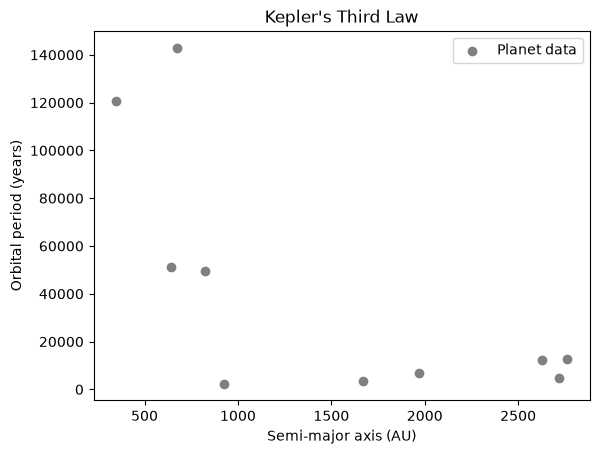

Fit: T = 0.14 * a^1.5
Reduced chi-squared: 4330777317.20


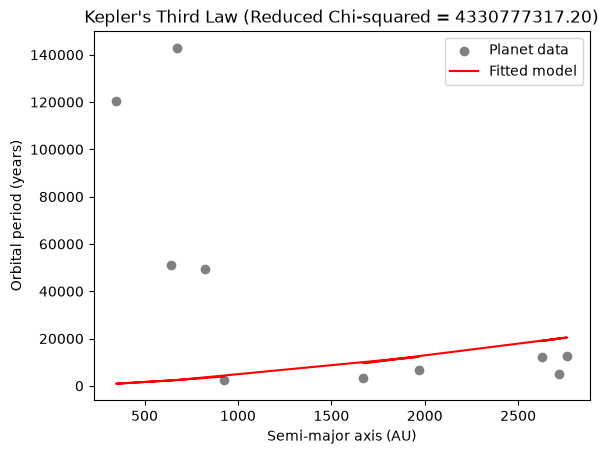

In [6]:
orbital_period = data.iloc[1, 1:].astype(float)
perihelion = data.iloc[2, 1:].astype(float)
aphelion = data.iloc[3, 1:].astype(float)

semi_major_axis = (perihelion + aphelion) / 2

new_row = pd.Series(["Semi-major axis (AU)"] + list(semi_major_axis))
data = pd.concat([data, new_row.to_frame().T], ignore_index=True)

plt.scatter(semi_major_axis, orbital_period, color="gray", label="Planet data")

plt.xlabel("Semi-major axis (AU)")
plt.ylabel("Orbital period (years)")
plt.title("Kepler's Third Law")
plt.legend()
plt.show()

def keplers_third_law(a, m):
    return m * a ** 1.5
    
valid = np.isfinite(semi_major_axis) & np.isfinite(orbital_period)

semi_major_axis = semi_major_axis[valid]
orbital_period = orbital_period[valid]

popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_period, p0=[1])

m_fit = popt[0]

print(f"Fit: T = {m_fit:.2f} * a^1.5")

residuals = orbital_period - keplers_third_law(semi_major_axis, m_fit)

chi2 = np.sum(residuals**2)

dof = len(semi_major_axis) - len(popt)

chi2_reduced = chi2 / dof

print(f"Reduced chi-squared: {chi2_reduced:.2f}")

plt.scatter(semi_major_axis, orbital_period, color="gray", label="Planet data")

plt.plot(semi_major_axis, keplers_third_law(semi_major_axis, m_fit),
         color="red", label="Fitted model")

plt.xlabel("Semi-major axis (AU)")
plt.ylabel("Orbital period (years)")
plt.title(f"Kepler's Third Law (Reduced Chi-squared = {chi2_reduced:.2f})")

plt.legend()
plt.show()

data.to_csv("kepler.csv", index=False)